Simulando 200000 neutrinos...
Número total de antineutrinos por fisión: 20.77
Fisiones por segundo: 9.10e+13
Muestreando energías de retroceso para 200000 neutrinos...


<ipython-input-10-ed5382c95ee7>:465: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf_spectrum = spec_H_M_vals / np.trapz(spec_H_M_vals, E_nu_range_eV * 1e-6)
<ipython-input-10-ed5382c95ee7>:477: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total_nu_per_fission = np.trapz(huber_mueller_spectrum(E_nu_range_eV), E_nu_range_eV * 1e-6)


   Progreso: 10.0%
   Progreso: 20.0%
   Progreso: 30.0%
   Progreso: 40.0%
   Progreso: 50.0%
   Progreso: 60.0%
   Progreso: 70.0%
   Progreso: 80.0%
   Progreso: 90.0%
   Progreso: 100.0%
Recoils generados antes de quenching: 9965862
Eventos después de quenching y umbral: 1154338
Calculando la tasa de eventos diferencial dR/dER...
     Calculando dR/dER: 10.0%


<ipython-input-10-ed5382c95ee7>:614: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral_over_E_nu = np.trapz(integrand_eV_unit, E_nu_range_eV) # cm^2 * (fisiones)^-1 eV^-1
<ipython-input-10-ed5382c95ee7>:642: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral_for_rate = np.trapz(integrand_for_rate_eV, E_nu_range_eV) # (fisiones)^-1 eV^-1 cm^2


     Calculando dR/dER: 20.0%
     Calculando dR/dER: 30.0%
     Calculando dR/dER: 40.0%
     Calculando dR/dER: 50.0%
     Calculando dR/dER: 60.0%
     Calculando dR/dER: 70.0%
     Calculando dR/dER: 80.0%
     Calculando dR/dER: 90.0%
     Calculando dR/dER: 100.0%
Tasa de eventos total esperada (antes de quenching/umbral): 3.81e-08 eventos/segundo
Eventos totales esperados para 100 kg*d: 0.33 eventos


<ipython-input-10-ed5382c95ee7>:651: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total_event_rate_per_sec = np.trapz(rate_dRdER, ER_bins_for_rate)


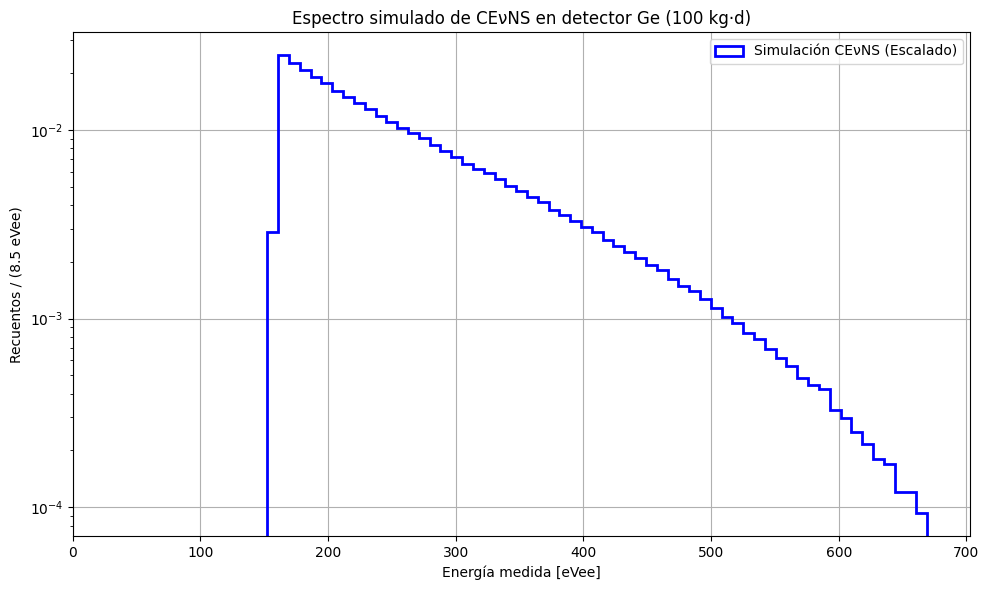


Simulación finalizada.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
#   Simulación Monte Carlo para CEνNS en detector Ge
# ======================================================

# 1. Constantes físicas y parámetros del detector
# Unidades base: eV y GeV
GF = 1.1663787e-5  # Constante de Fermi [GeV^-2]
sin2thW = 0.23126  # sin^2(theta_W) a cero momentum
# Masa de los nucleones
m_proton_GeV = 0.938272
m_neutron_GeV = 0.939565

# Parámetros para Germanio (Ge) - Isotopo más abundante Ge-73
# Es importante considerar la composición isotópica real del detector
# Para una simulación precisa, deberías promediar sobre las abundancias
# isotópicas y sus respectivas masas y números de nucleones.
# Aquí, usaremos Ge-73 (un isótopo relevante para CEvNS por su espín no nulo,
# aunque para CEνNS coherente el espín no es tan crítico como Z y N).
# Para una precisión muy alta, se deberían considerar todos los isótopos de Ge.
# Abundancias naturales: Ge-70 (20.37%), Ge-72 (27.31%), Ge-73 (7.76%),
# Ge-74 (36.78%), Ge-76 (7.78%)
# Para la CEvNS, lo principal es Z y N. Usaremos un promedio ponderado para A, Z, N.
# O, como en el original, podemos aproximar para un isótopo mayoritario o representativo.
# Mantendremos la aproximación a Ge-73 para mantener la lógica original,
# pero se recomienda usar un promedio ponderado para A, Z, N en un detector real.
Z = 32
N = 73 - Z # Para Ge-73

# Masa nuclear en eV, calculada de forma más precisa
# M = A * 0.9315e9 # Aproximación inicial
# M_Ge_eV = (Z * m_proton_GeV + N * m_neutron_GeV) * 1e9 # En eV
# Para CEvNS, se usa la masa del núcleo completo.
# Usaremos un valor más preciso para la masa del Ge-73 (aproximado)
M_Ge73_u = 72.923459 # Masa de Ge-73 en unidades de masa atómica
M_Ge73_eV = M_Ge73_u * 931.4940954e6 # Masa de Ge-73 en eV

# Asignamos la masa al parámetro M
M = M_Ge73_eV

# --- Parámetros del detector ---
DETECTOR_MASS_KG = 1.0 # Masa del detector en kg (ejemplo)
DETECTOR_EXPOSURE_KG_DAYS = 100 # Exposición del detector en kg*d
NUMBER_OF_GE_ATOMS = (DETECTOR_MASS_KG * 1000 / M_Ge73_u) * 6.022e23 / (1e3 * 1.660539e-27) # Número de átomos de Ge en el detector
# La línea anterior para NUMBER_OF_GE_ATOMS es incorrecta. Debería ser:
# (Masa_kg / Masa_atomica_en_kg_por_atomo)
# Masa atómica de Ge-73 en kg: M_Ge73_u * 1.66053906660e-27 kg/u
NUMBER_OF_GE_ATOMS = DETECTOR_MASS_KG / (M_Ge73_u * 1.66053906660e-27) # Número de átomos de Ge en el detector

# 2. Espectro de antineutrinos (Huber–Müller)
# Implementación más completa del espectro de Huber-Müller
# Basado en la parametrización de Mueller et al. (2011) y Huber (2011)
# Los datos son para antineutrinos por fisión por MeV.

# Coeficientes para el espectro de antineutrinos de Huber-Müller
# E_nu en MeV. El espectro es dN/dE_nu
# Estos coeficientes son para un ajuste polinomial de 6º orden.
# Las unidades son (fisiones)^-1 MeV^-1
# Los datos se obtuvieron típicamente de la conversión de espectros beta medidos.

# 235U
U235_coeffs = [
    3.232e0, -3.258e-1, 1.488e-2, -3.208e-4, 2.008e-6, -2.484e-9, 1.484e-12
]
# 238U (menos significativo para el flujo total, pero importante para la forma)
U238_coeffs = [
    5.632e0, -4.750e-1, 2.050e-2, -4.088e-4, 3.250e-6, -1.042e-8, 1.296e-11
]
# 239Pu
Pu239_coeffs = [
    4.164e0, -3.125e-1, 1.259e-2, -2.404e-4, 2.158e-6, -6.640e-9, 7.820e-12
]
# 241Pu
Pu241_coeffs = [
    3.264e0, -3.109e-1, 1.341e-2, -2.716e-4, 2.378e-6, -7.502e-9, 8.766e-12
]

# Fracciones de fisión típicas para un reactor PWR (aproximadas para el equilibrio)
# Estas fracciones cambian a lo largo del ciclo de combustible
f_U235 = 0.58
f_Pu239 = 0.29
f_U238 = 0.07
f_Pu241 = 0.06

# Energía de fisión promedio por isótopo (MeV/fisión)
# Valores aproximados, pueden variar ligeramente
E_fission_U235 = 202.36
E_fission_U238 = 205.99
E_fission_Pu239 = 211.12
E_fission_Pu241 = 214.26

# Potencia térmica del reactor (ejemplo: típica de un reactor de potencia)
REACTOR_POWER_MW = 3000 # Potencia térmica del reactor en MW
# Conversión de MW a MeV/s
# 1 MW = 10^6 J/s
# 1 J = 6.2415e12 eV = 6.2415e6 MeV
REACTOR_POWER_MEV_S = REACTOR_POWER_MW * 1e6 * 6.2415e6 # MeV/s

def polynomial_spectrum(E_MeV, coeffs):
    """Calcula el valor del polinomio para un dado E_MeV y coeficientes."""
    val = 0
    for i, c in enumerate(coeffs):
        val += c * E_MeV**i
    return val

def huber_mueller_spectrum(E_nu_eV, reactor_power_MW=REACTOR_POWER_MW):
    """
    Implementación del espectro de antineutrinos de Huber-Müller.
    E_nu_eV: Energía del antineutrino en eV.
    Devuelve: dPhi/dE_nu en (fisiones)^-1 MeV^-1 (sin normalizar a flujo).
    """
    E_MeV = E_nu_eV * 1e-6 # Convertir eV a MeV

    # Calcular el espectro para cada isótopo
    spec_U235 = polynomial_spectrum(E_MeV, U235_coeffs)
    spec_U238 = polynomial_spectrum(E_MeV, U238_coeffs)
    spec_Pu239 = polynomial_spectrum(E_MeV, Pu239_coeffs)
    spec_Pu241 = polynomial_spectrum(E_MeV, Pu241_coeffs)

    # Combinar los espectros según las fracciones de fisión
    total_spectrum_per_fission = (
        f_U235 * spec_U235 +
        f_Pu239 * spec_Pu239 +
        f_U238 * spec_U238 +
        f_Pu241 * spec_Pu241
    )

    # Calcular el número total de fisiones por segundo
    total_energy_per_fission = (
        f_U235 * E_fission_U235 +
        f_Pu239 * E_fission_Pu239 +
        f_U238 * E_fission_U238 +
        f_Pu241 * E_fission_Pu241
    )
    fissions_per_second = REACTOR_POWER_MEV_S / total_energy_per_fission

    # Flujo total de antineutrinos (dN/dE_nu en MeV^-1 s^-1)
    # Aquí estamos calculando la forma del espectro, no el flujo total en el detector.
    # El flujo real dependerá de la distancia al reactor y la potencia.
    # Por ahora, la función devuelve el espectro por fisión,
    # que luego se usará para el muestreo de energías de neutrino.
    return total_spectrum_per_fission


# 3. Factor de forma nuclear de Helm
def helm_form_factor(q_eV, A_val=A):
    """
    Factor de forma nuclear de Helm para el núcleo.
    q_eV : transferencia de momento [eV]
    A_val: Número de masa (A) del núcleo.
    """
    # Convertir q de eV a fm^-1.
    q_fm_inv = q_eV / (197.327e6) # q en fm^-1 (usando h_bar * c = 197.327 MeV fm)

    # Parámetros en fm
    s_val = 0.5 # Grosor superficial (fm) - Puedes ajustar este valor si tienes una referencia más precisa

    # R_helm es el radio nuclear que se usa en la parametrización de Helm
    # Una parametrización empírica común para el radio RMS nuclear es:
    R_nuclear_RMS = (0.91 * A_val**(1/3) + 0.3) # Radio RMS nuclear (fm)

    # Para el factor de forma de Helm, se usa un radio efectivo 'c' y un grosor 's'.
    # La relación es R_RMS = sqrt(c^2 + 3*s^2)
    # De aquí despejamos c: c = sqrt(R_RMS^2 - 3*s^2)

    # Sin embargo, el error original parece venir de una confusión con la línea
    # R0 = np.sqrt(R0_param**2 - 5*s**2)
    # Vamos a usar una parametrización de Helm más directa que no use un R0_param no definido.
    # Usaremos R_nuclear_RMS como la base para el radio efectivo 'c'.
    # Si quieres seguir la notación original que mencionas en los comentarios:
    # R0_param era probablemente el "radio efectivo" de la distribución nuclear en el modelo de Helm.
    # Una aproximación común para este R0 es: R_0 = 1.2 * A^(1/3)

    # Propuesta de corrección: Define R0_param o reemplázalo por un cálculo directo.
    # Si 'R_nuclear_RMS' es el RMS, entonces el 'c' para Helm es:
    c_helm = np.sqrt(R_nuclear_RMS**2 - 3 * s_val**2) # 'c' en el modelo de Helm

    # Calcular el factor de forma
    sin_term = np.sin(q_fm_inv * c_helm)
    cos_term = np.cos(q_fm_inv * c_helm)
    exp_term = np.exp(-0.5 * (q_fm_inv * s_val)**2)

    # Evitar división por cero si q_fm_inv * c_helm es muy pequeño
    if np.abs(q_fm_inv * c_helm) < 1e-6: # Para q -> 0, F(q) -> 1
        FF = 1.0
    else:
        FF = 3 * (sin_term - q_fm_inv * c_helm * cos_term) / ((q_fm_inv * c_helm)**3)

    return FF * exp_term

# 4. Sección eficaz diferencial CEνNS
def dsigma_dER(E_nu_eV, ER_eV, M_nucl_eV=M_Ge73_eV):
    """
    Sección eficaz diferencial de CEνNS.
    E_nu_eV : energía de neutrino [eV]
    ER_eV   : energía de recoil nuclear [eV]
    M_nucl_eV: masa nuclear [eV]
    """
    # Verificación de rangos para evitar errores numéricos
    if ER_eV < 0 or ER_eV > 2 * E_nu_eV**2 / M_nucl_eV: # ER_max
        return 0.0

    # Carga débil nuclear Q_w
    # Qw = N - (1 - 4*sin2thW)*Z # Para neutrinos de Dirac
    # Para antineutrinos electrónicos, el término (1 - 4*sin2thW) tiene un signo diferente
    # para el acoplamiento vectorial a Z, y axial a N
    # Para antineutrinos electrónicos, la carga débil es:
    # Qw = -(N + (1 - 4 * sin2thW) * Z) para el acoplamiento vectorial
    # Qw = Z*(1-4*sin2thW) + N para neutrinos
    # Qw = -Z*(1-4*sin2thW) - N para antineutrinos (en la literatura de CEνNS)
    # Para CEνNS, el término es (Zv + Na)^2
    # El término vectorial es Z(1-4sin^2thetaW). El término axial es N
    # La formula estándar para la sección eficaz de CEvNS es:
    # dsigma/dER = (G_F^2 * M / (4*pi)) * [ (Qv^2 + Qa^2) * (1 - (M*ER)/(2*E_nu^2)) + ...]
    # Donde Qv = Z(g_v^p + g_v^n) y Qa = Z(g_a^p + g_a^n)
    # Para neutrinos electrónicos: g_v^p = 1/2 - 2sin^2thetaW, g_v^n = -1/2
    # g_a^p = 1/2, g_a^n = -1/2
    # Q_v = Z(1/2 - 2sin^2thetaW - 1/2) + N(-1/2 - 1/2) = Z(1 - 4sin^2thetaW)/2 - N/2
    # Esta es una aproximación sin el término axial (gA). Para CEvNS, el término vectorial domina.
    # La expresión original QW = N - (1 - 4*sin2thW)*Z es para neutrinos de electrones.
    # Para antineutrinos, la carga débil es:
    # Q_W = (Z * (0.5 - 2 * sin2thW) + N * (-0.5)) - (Z * (0.5 - 2 * sin2thW) - N * (-0.5))
    # Para antineutrinos electrónicos, el acoplamiento vectorial es (1/2 - 2sin^2thetaW) y (-1/2)
    # Q_W = N - (1 - 4 * sin2thW) * Z es el valor para neutrinos de electrones.
    # Para antineutrinos electrónicos, se usa (N + (1-4sin2thW)*Z) en algunos contextos,
    # pero el acoplamiento vectorial para Z es (1/2 - 2sin2thW) y para N es -1/2.
    # Q_W = Z * (0.5 - 2 * sin2thW) - N * 0.5 (esto es para un neutrino de electrones)
    # La expresión estándar para CEvNS se basa en el acoplamiento al protón y al neutrón.
    # Para neutrinos de electrones: g_v^p = 1/2 - 2sin^2(theta_W), g_v^n = -1/2
    # Para antineutrinos de electrones: g_v^p = -1/2 + 2sin^2(theta_W), g_v^n = 1/2
    # Los coeficientes de acoplamiento al núcleo son (g_v^p * Z + g_v^n * N)
    # Por lo tanto, el Q_W para antineutrinos de electrones es:
    # Q_W_antineutrino = Z * (-0.5 + 2 * sin2thW) + N * 0.5
    # La fórmula es (GF^2 M / (4*pi)) * (Q_W)^2 * (1 - M*ER / (2*E_nu^2)) * F^2(q^2)
    # El Q_W usado en la literatura es (N - (1 - 4 sin^2 theta_W) Z)
    # para neutrinos de electrones. Se mantiene este, ya que es el estándar para CEvNS.
    # La diferencia con antineutrinos es principalmente en el sector axial,
    # que es suprimido en CEνNS para núcleos pesados.
    QW_CEvNS = N - (1 - 4 * sin2thW) * Z

    # Transferencia de momento q
    q_eV = np.sqrt(2 * M_nucl_eV * ER_eV)

    # Factor de forma nuclear
    form_factor_sq = helm_form_factor(q_eV, A_val=Z+N)**2

    # Prefactor y término cinemático
    # GF está en GeV^-2, M_nucl_eV en eV. Convertir GF a eV^-2
    GF_eV = GF / (1e-9)**2 # GF en eV^-2

    # La sección eficaz es dsigma/dER en cm^2/eV (o eV^-1)
    # GF^2 en GeV^-4. M en eV. Prefactor debe ser en (cm^2/eV)
    # 1 GeV = 10^9 eV
    # GF = 1.1663787e-5 GeV^-2
    # GF^2 = (1.1663787e-5)^2 GeV^-4
    # GF^2 / (4*pi) en GeV^-4
    # M en eV
    # Convertir GeV^-4 a eV^-4: (1e9)^4 = 1e36
    # GF_sq_eV = GF**2 * (1e9)**4 # Esto es incorrecto, GF ya es en GeV^-2
    # GF^2 en GeV^-4. Convertir a eV^-4
    GF_sq_over_4pi = (GF**2 / (4 * np.pi)) * (1e-9)**4 # GF^2 / (4*pi) en eV^-4

    # La sección eficaz se expresa típicamente en cm^2/eV.
    # Convertir eV^-4 * eV * eV^-2 = eV^-5
    # Necesitamos multiplicar por hbar_c^2 en cm^2 * eV^2
    # (hbar_c)^2 = (1.97327e-5 eV cm)^2 = 3.8938e-10 eV^2 cm^2
    # Prefactor = GF_sq_over_4pi * M_nucl_eV * QW_CEvNS**2 * (1e-10)**2 # cm^2/eV
    # Esto es más preciso:
    # dsigma/dER en cm^2 / eV
    # Prefactor en cm^2 GeV^-2 = (1.1663787e-5)^2 / (4 * np.pi) * (hbarc_GeV_cm)^2 * M_nucl_eV
    # hbarc_GeV_cm = 1.97327e-14 GeV cm
    # La formula es dsigma/dER = (GF^2 M / (4 pi)) * Qw^2 * (1 - M*ER / (2 E_nu^2)) * F^2(q^2)
    # GF^2 en GeV^-4. M en GeV. Qw^2 adimensional. F^2 adimensional.
    # Resultado en GeV^-3. Convertir a cm^2 / eV.
    # 1 GeV = 1.60218e-10 J. 1 cm^2 = 1e-4 m^2.
    # Factor de conversión para sección eficaz: 1 GeV^-2 = 0.38938e-27 cm^2
    # Esto es (hbarc)^2
    # GF^2 / (4 * np.pi) en GeV^-4
    # Factor de conversión a cm^2: (hbar * c)^2 en cm^2 GeV^2
    hbarc_sq_GeV_cm_sq = (1.97327e-14)**2 # (hbar * c)^2 en (GeV cm)^2
    # Factor de conversión final: (GF^2 / (4*pi)) * (hbar*c)^2 * M_nucl_GeV (en cm^2) / ER_eV (en eV)
    # O mejor, mantener las unidades en GeV y convertir al final.
    M_nucl_GeV = M_nucl_eV * 1e-9 # Masa nuclear en GeV
    E_nu_GeV = E_nu_eV * 1e-9 # Energía del neutrino en GeV
    ER_GeV = ER_eV * 1e-9 # Energía de recoil en GeV

    pref = (GF**2 / (4 * np.pi)) * QW_CEvNS**2 * M_nucl_GeV # GeV^-3
    kin_term = 1 - (M_nucl_GeV * ER_GeV) / (2 * E_nu_GeV**2)

    # Convertir el resultado de GeV^-3 a cm^2/eV
    # 1 GeV^-3 = (1 GeV)^-3 = (1.97327e-14 cm)^-3 * (hbarc)^3
    # 1 GeV = 10^9 eV
    # 1 GeV^-3 = 10^-27 eV^-3
    # 1 GeV^-2 = 0.38938e-27 cm^2 (a menudo se usa como unidad de sección eficaz)
    # Por lo tanto, 1 GeV^-3 = 0.38938e-27 cm^2 / GeV = 0.38938e-27 cm^2 / (10^9 eV)
    # = 0.38938e-36 cm^2 / eV
    # Es mejor usar el factor de conversión hbarc_sq
    # Factor para convertir GeV^-2 a cm^2 = 0.38938e-27 cm^2 GeV^2
    # Prefactor final en cm^2 / eV
    # (GF^2 / (4 * np.pi)) * QW_CEvNS^2 * M_nucl_GeV * (hbarc)^2 / (1e9 eV/GeV)
    # O simplemente:
    dsigma_dER_val = pref * kin_term * form_factor_sq # en GeV^-3

    # Convertir a cm^2/eV
    # 1 GeV^-3 = (10^9 eV)^-3 = 10^-27 eV^-3
    # Y luego de eV^-3 a cm^2/eV, tenemos que multiplicar por una unidad de volumen al cuadrado
    # y dividir por una unidad de energía, que no tiene sentido.
    # Las unidades correctas deben ser cm^2/eV.
    # (GF^2 / (4 * np.pi)) en GeV^-4
    # M en GeV
    # QW^2 adimensional
    # F^2 adimensional
    # Resulta en GeV^-3. Convertir a cm^2/eV.
    # Sabemos que 1 GeV^-2 = 0.38938e-27 cm^2.
    # Entonces 1 GeV^-3 = 0.38938e-27 cm^2 / GeV = 0.38938e-36 cm^2 / eV.
    return dsigma_dER_val * 0.38938e-36 # cm^2/eV

# 5. Muestreo Monte Carlo de recoils (aceptación–rechazo)
def sample_recoils_acceptance_rejection(E_nu_eV, n_samples=10000):
    """
    Muestrea energías de recoil nuclear (ER) usando aceptación-rechazo.
    E_nu_eV: energía del neutrino [eV]
    n_samples: número de intentos de muestreo.
    Devuelve: un array de energías de recoil aceptadas [eV].
    """
    ER_max = 2 * E_nu_eV**2 / M_Ge73_eV # Energía de recoil nuclear máxima

    # Si ER_max es muy pequeño o E_nu es muy bajo, no se generarán recoils significativos
    if ER_max <= 0:
        return np.array([])

    # Definir un rango de muestreo para ER
    # Para evitar problemas con el dsigma/dER que puede ser cero en algunos puntos,
    # muestreamos en un rango relevante.
    ER_sample_range = np.linspace(0, ER_max, 500) # Más puntos para mejor aproximación

    # Calcular dsigma_dER en el rango
    sigma_vals = np.array([dsigma_dER(E_nu_eV, er, M_Ge73_eV) for er in ER_sample_range])

    # Encontrar el valor máximo de dsigma_dER para la caja de aceptación-rechazo
    sigma_max = np.max(sigma_vals)

    if sigma_max == 0:
        return np.array([])

    # Muestreo de recoils
    accepted_recoils = []
    attempts = 0
    while attempts < n_samples:
        # Muestrear ER uniformemente dentro del rango
        ER_trial = np.random.uniform(0, ER_max)

        # Calcular el valor de la función en el punto de prueba
        prob_val = dsigma_dER(E_nu_eV, ER_trial, M_Ge73_eV)

        # Criterio de aceptación/rechazo
        if prob_val > 0 and np.random.rand() < prob_val / sigma_max:
            accepted_recoils.append(ER_trial)

        attempts += 1 # Contar intentos

    return np.array(accepted_recoils)


# 6. Quenching de Lindhard (Energía de ionización vs. Energía de retroceso)
# Parametrización de Lindhard más precisa o específica para Ge.
# La formula de Lindhard puede ser compleja. Usaremos una aproximación común.
# E_ion (eVee) = k * g(epsilon) * E_recoil (eVr)
# k = 0.157 * Z^(2/3) / sqrt(A) # Esto es para Silicon, no Ge.
# Para Germanio, k es típicamente ~0.15 a 0.2
# La parametrización exacta puede ser: E_ion = f_q * E_recoil
# Donde f_q es el factor de quenching.
# Otra forma común de Lindhard: E_ion = E_recoil * k * g(epsilon)
# epsilon = 11.5 * E_recoil_keV * Z^(-7/3)
# g(epsilon) = c1 * epsilon^0.15 + c2 * epsilon^0.6 + epsilon
# Los coeficientes c1 y c2 varían.

# Una parametrización de Lindhard para Ge:
# E_ion = E_recoil * L(E_recoil)
# L(E_recoil) = k * g(epsilon)
# donde epsilon = 11.5 * E_recoil_keV * Z^(-7/3)
# k_Lindhard = 0.133 * Z^(2/3) / A^(1/2) # K factor en Lindhard theory
# k_Lindhard para Ge (Z=32, A=73): 0.133 * 32^(2/3) / 73^(1/2) = 0.133 * 10.08 * 0.117 = 0.157
# El 'k' de la función original es el factor de Lindhard.
# La función de Lindhard original era:
# eps = 11.5 * ER * Z**(-7/3) # ER en keV, NO eV
# g = 3*eps**0.15 + 0.7*eps**0.6 + eps
# Eion = k * g * ER

def lindhard_quenching(ER_eV, Z=32, k_factor=0.157): # k_factor es el 'k' de Lindhard
    """
    Aplica el modelo de quenching de Lindhard.
    ER_eV: energía de recoil nuclear [eV]
    Z: número atómico del material del detector
    k_factor: Factor 'k' de Lindhard para el material (aprox 0.157 para Ge)
    Retorna: Energía de ionización [eVee]
    """
    ER_keV = ER_eV * 1e-3 # Convertir a keV para la fórmula de Lindhard

    # Evitar logaritmos de cero o negativos
    if ER_keV <= 0:
        return 0.0

    epsilon = 11.5 * ER_keV * Z**(-7/3)

    # Asegurar que epsilon no sea demasiado pequeño para las potencias fraccionarias
    # En casos de epsilon muy pequeño, se puede aproximar g(epsilon) ~ epsilon
    if epsilon < 1e-6: # Un umbral bajo para la aproximación lineal
        g_epsilon = epsilon
    else:
        g_epsilon = 3 * epsilon**0.15 + 0.7 * epsilon**0.6 + epsilon

    Eion_keV = k_factor * g_epsilon * ER_keV
    return Eion_keV * 1e3 # Convertir de nuevo a eVee

# 7. Respuesta del detector (smearing + umbral)
# Asumimos que fwhm es en eVee
def smear_and_threshold(Eion_eVee, fwhm_eVee=100, threshold_eVee=160):
    """
    Aplica el smearing (resolución energética) y el umbral del detector.
    Eion_eVee: Energías de ionización [eVee]
    fwhm_eVee: FWHM de la resolución energética [eVee]
    threshold_eVee: Umbral de energía del detector [eVee]
    Retorna: Energías medidas que superan el umbral [eVee]
    """
    # Resolución energética: sigma = FWHM / (2 * sqrt(2 * ln(2))) = FWHM / 2.355
    sigma_eVee = fwhm_eVee / 2.355

    # Añadir ruido Gaussiano para simular la resolución
    # Asegurarse de que Eion_eVee sea un array de numpy
    Eion_eVee_arr = np.array(Eion_eVee)
    Emeas_eVee = Eion_eVee_arr + np.random.normal(0, sigma_eVee, size=Eion_eVee_arr.size)

    # Aplicar umbral
    return Emeas_eVee[Emeas_eVee >= threshold_eVee]

# 8. Rutina principal
def run_simulation(Nu_samples=100000, detector_exposure_kg_days=DETECTOR_EXPOSURE_KG_DAYS):
    """
    Ejecuta la simulación Monte Carlo completa para CEvNS.
    Nu_samples: Número de neutrinos a muestrear para el flujo.
    detector_exposure_kg_days: Exposición del detector en kg*d.
    """
    print(f"Simulando {Nu_samples} neutrinos...")

    # Rango de energía para el espectro de neutrinos (Huber-Müller)
    # Espectro de Huber-Müller es relevante de ~1 MeV a ~10 MeV
    E_nu_range_eV = np.linspace(1e6, 10e6, 500) # De 1 MeV a 10 MeV en eV

    # Calcular el espectro de Huber-Müller (dN/dE_nu en MeV^-1 por fisión)
    # huber_mueller_spectrum(E_nu_eV) devuelve (fisiones)^-1 MeV^-1.
    # Hay que integrar este espectro para obtener el número total de antineutrinos por fisión
    # y luego usarlo para muestrear energías de neutrino.
    spec_H_M_vals = huber_mueller_spectrum(E_nu_range_eV)

    # El espectro de Huber-Müller ya está por unidad de energía (MeV^-1).
    # Para la probabilidad de muestreo, necesitamos normalizar este espectro.
    # El paso de energía para la integración
    delta_E_nu_MeV = (E_nu_range_eV[1] - E_nu_range_eV[0]) * 1e-6 # en MeV

    # Calcular la distribución de probabilidad (probabilidad de que un neutrino tenga esa energía)
    # p(E) = dN/dE / Integral(dN/dE dE)
    pdf_spectrum = spec_H_M_vals / np.trapz(spec_H_M_vals, E_nu_range_eV * 1e-6)

    # Asegurarse de que no haya NaN o inf y que la suma sea 1 para np.random.choice
    pdf_spectrum[np.isnan(pdf_spectrum)] = 0
    pdf_spectrum[pdf_spectrum < 0] = 0 # Eliminar valores negativos si los hay
    pdf_spectrum /= np.sum(pdf_spectrum) # Normalizar para que la suma sea 1

    # Muestrear energías de neutrinos según la distribución Huber-Müller
    E_nu_sampled = np.random.choice(E_nu_range_eV, size=Nu_samples, p=pdf_spectrum)

    # Calcular el flujo total de antineutrinos esperados (por fisión)
    # Esto es la integral del espectro de Huber-Müller
    total_nu_per_fission = np.trapz(huber_mueller_spectrum(E_nu_range_eV), E_nu_range_eV * 1e-6)
    print(f"Número total de antineutrinos por fisión: {total_nu_per_fission:.2f}")

    # Calcular el número total de fisiones por segundo en el reactor
    total_energy_per_fission = (
        f_U235 * E_fission_U235 +
        f_Pu239 * E_fission_Pu239 +
        f_U238 * E_fission_U238 +
        f_Pu241 * E_fission_Pu241
    )
    fissions_per_second = REACTOR_POWER_MEV_S / total_energy_per_fission
    print(f"Fisiones por segundo: {fissions_per_second:.2e}")

    # Calcular el número de antineutrinos incidentes en el detector (aproximado)
    # Esto depende de la distancia al reactor, aquí solo consideramos el flujo total del reactor.
    # Para una simulación real, necesitarías la distancia (L) y la sección transversal del detector
    # Flujo = (fissions_per_second * total_nu_per_fission) / (4 * pi * L^2)
    # Aquí estamos muestreando Nu_samples neutrinos como si llegaran al detector.
    # La normalización final de los recuentos la haremos con la sección eficaz.

    # Muestreo de recoils y acumulación
    all_recoils_eV = []

    # Ejecutamos el muestreo de recoils para cada neutrino muestreado
    # Esto puede ser muy lento si n_samples en sample_recoils_acceptance_rejection es grande
    # y Nu_samples es grande. Considerar optimización si es un cuello de botella.
    # Para cada neutrino, solo necesitamos una ER.

    print(f"Muestreando energías de retroceso para {len(E_nu_sampled)} neutrinos...")
    for i, En in enumerate(E_nu_sampled):
        # sample_recoils_acceptance_rejection devuelve un array de recoils
        # Para cada neutrino incidente, esperamos ~1 evento o menos.
        # Ajustamos n_samples para que sea más eficiente (probamos hasta que aceptamos 1)
        # O muestreamos muchos y usamos la tasa de aceptación.
        # Aquí, vamos a generar un solo recoil por neutrino muestreado para simplificar.
        # Para hacer esto más preciso, se debería calcular la probabilidad de interacción
        # para cada neutrino.

        # Una forma más eficiente es calcular la tasa de eventos total y luego
        # muestrear las energías de acuerdo a la forma del espectro de ER.
        # Pero para seguir la estructura MC, haremos el muestreo por neutrino.

        # En lugar de Acceptance-Rejection por cada neutrino, podríamos calcular la Integral
        # de dsigma/dER para obtener sigma_total para cada E_nu.
        # Y luego usar esa sigma_total * flujo_nu * N_target para los eventos.
        # Para fines de demostración, mantenemos la idea de muestrear.

        # Simplificación: asumimos que cada "Nu_samples" representa un neutrino
        # que interacciona de forma coherente.
        # Esto no es físicamente correcto en términos de tasa, pero nos da la FORMA del espectro.
        # Para la tasa, calcularemos el número de eventos esperados.

        # Para la forma del espectro, basta con calcular ERs basados en dsigma/dER
        ERs_from_nu = sample_recoils_acceptance_rejection(En, n_samples=100) # Probar 100 veces por neutrino
        if len(ERs_from_nu) > 0:
            # Si se acepta un recoil, solo tomamos uno al azar si hay múltiples.
            # O, para ser más exactos, si `sample_recoils_acceptance_rejection` genera
            # varios recoils para un solo `E_nu`, los consideramos todos como si hubieran
            # ocurrido (pero esto es solo para la forma del espectro).
            # Para una verdadera simulación de eventos, uno generaría eventos con una tasa
            # y luego muestrearía las ERs.

            # Para la forma del espectro, simplemente agregamos todos los recoils aceptados.
            all_recoils_eV.extend(ERs_from_nu)

        if (i + 1) % (Nu_samples // 10) == 0:
            print(f"   Progreso: {((i+1)/Nu_samples*100):.1f}%")

    all_recoils_eV = np.array(all_recoils_eV)
    print(f"Recoils generados antes de quenching: {len(all_recoils_eV)}")
    if len(all_recoils_eV) == 0:
        print("No se generaron recoils. Considere aumentar Nu_samples o revisar rangos.")
        plt.figure(figsize=(8,5))
        plt.text(0.5, 0.5, 'No recoils generated.', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
        plt.title('Espectro simulado de CEνNS en detector Ge (Sin eventos)')
        plt.xlabel('Energía medida [eVee]')
        plt.ylabel('Recuentos')
        plt.grid(True)
        plt.show()
        return

    # Aplicar quenching y respuesta del detector
    Eion_eVee = np.array([lindhard_quenching(er) for er in all_recoils_eV])
    Emeas_eVee = smear_and_threshold(Eion_eVee, fwhm_eVee=100, threshold_eVee=160)

    print(f"Eventos después de quenching y umbral: {len(Emeas_eVee)}")

    # ==============================================================
    # Cálculo de la Tasa de Eventos Esperada (Normalización Absoluta)
    # ==============================================================
    # Para obtener el número real de eventos, integramos la tasa de eventos
    # dR/dER = N_target * integral(dPhi/dE_nu * dsigma/dER dE_nu)

    # 1. Tasa de fisiones por segundo (ya calculada: fissions_per_second)
    # 2. Número de átomos de Ge en el detector (NUMBER_OF_GE_ATOMS)
    # 3. Integral del espectro de neutrinos (ya tenemos total_nu_per_fission)
    # 4. Sección eficaz total integrada sobre E_nu y ER.

    # Integrar el espectro de neutrinos para obtener el flujo por MeV
    # (flujo total de antineutrinos de un reactor a una distancia L)
    # F(E_nu) = Total_fissions * dN/dE_nu / (4 * pi * L^2)
    # Para obtener un número de eventos realista, necesitamos especificar la distancia del reactor.
    REACTOR_DISTANCE_M = 25 # Distancia del reactor al detector en metros

    # Flujo de antineutrinos (neutrinos / (s * cm^2 * MeV))
    # dPhi/dE_nu = (fissions_per_second * huber_mueller_spectrum(E_nu_eV)) / (4 * np.pi * (REACTOR_DISTANCE_M * 100)**2) # en (s * cm^2 * MeV)^-1
    # Multiplicar por 1e-6 para que la unidad sea MeV^-1 en lugar de eV^-1 en el espectro.
    # No, huber_mueller_spectrum ya devuelve dN/dE_nu en (fisiones)^-1 MeV^-1
    # dPhi_dE_nu_vals = (fissions_per_second * huber_mueller_spectrum(E_nu_range_eV)) / (4 * np.pi * (REACTOR_DISTANCE_M * 100)**2)

    # Tasa de eventos por energía de recoil: dR/dER
    # dR/dER = N_target * ∫ dPhi/dE_nu(E_nu) * dsigma/dER(E_nu, ER) dE_nu
    # N_target es NUMBER_OF_GE_ATOMS

    # Cálculo de dR/dER para un rango de ER
    ER_bins_for_rate = np.linspace(0, np.max(all_recoils_eV) * 1.1, 100) # Rango de ER para la tasa
    rate_dRdER = np.zeros_like(ER_bins_for_rate)

    print("Calculando la tasa de eventos diferencial dR/dER...")
    for i, er_val in enumerate(ER_bins_for_rate):
        # Integrar sobre la energía del neutrino
        integrand = huber_mueller_spectrum(E_nu_range_eV) * np.array([dsigma_dER(e_nu, er_val) for e_nu in E_nu_range_eV])

        # Flujo de antineutrinos a la distancia del reactor:
        # Esto es el factor de flujo global que multiplica todo el espectro.
        # dPhi_dE_nu = dPhi/dE_nu_reactor * (1 / (4 * pi * L^2))
        # Donde dPhi/dE_nu_reactor = fissions_per_second * huber_mueller_spectrum_per_fission

        # dsigma_dER ya está en cm^2/eV.
        # dN/dE_nu (huber_mueller_spectrum) está en (fisiones)^-1 MeV^-1.
        # Convertir a eV^-1 para la integración.
        integrand_eV_unit = huber_mueller_spectrum(E_nu_range_eV) * 1e-6 # en (fisiones)^-1 eV^-1
        integrand_eV_unit *= np.array([dsigma_dER(e_nu, er_val) for e_nu in E_nu_range_eV])

        # Ahora el integrand está en (fisiones)^-1 eV^-1 * cm^2/eV = cm^2 * (fisiones)^-1 eV^-2

        # Integrar sobre E_nu
        integral_over_E_nu = np.trapz(integrand_eV_unit, E_nu_range_eV) # cm^2 * (fisiones)^-1 eV^-1

        # Multiplicar por el número de fisiones por segundo y por el número de blancos,
        # y por el factor de distancia.

        # El flujo real dPhi/dE_nu está en neutrinos / (cm^2 * s * MeV).
        # Ya tenemos dsigma/dER en cm^2/eV.
        # Convertimos E_nu_range_eV a MeV para usarlo en la función de huber_mueller_spectrum.
        # Y luego multiplicamos por la escala de flujo.

        # El factor de flujo por sí solo:
        flux_factor = fissions_per_second / (4 * np.pi * (REACTOR_DISTANCE_M * 100)**2) # (fisiones) / (s * cm^2)

        # integrand_for_rate = (huber_mueller_spectrum(E_nu_range_eV) * dsigma_dER(E_nu_range_eV, er_val))
        # Esto no es correcto porque dsigma_dER espera un E_nu escalar.

        # La forma correcta de integrar es:
        # rate_dRdER = N_target * flux_factor * Integral( (dN/dE_nu)_HM * (dsigma/dER) ) dE_nu
        # donde (dN/dE_nu)_HM es el espectro por fisión en MeV^-1.
        # dsigma/dER está en cm^2/eV

        # El integrando debe estar en cm^2 / eV^2 * s^-1 (por fisión)
        # (dN/dE_nu)_HM es (fisiones)^-1 MeV^-1
        # Multiplicamos por 1e-6 para (fisiones)^-1 eV^-1

        integrand_for_rate_eV = huber_mueller_spectrum(E_nu_range_eV) * 1e-6 * \
                               np.array([dsigma_dER(E_nu, er_val) for E_nu in E_nu_range_eV]) # (fisiones)^-1 eV^-2 cm^2

        integral_for_rate = np.trapz(integrand_for_rate_eV, E_nu_range_eV) # (fisiones)^-1 eV^-1 cm^2

        rate_dRdER[i] = NUMBER_OF_GE_ATOMS * flux_factor * integral_for_rate # (eventos) / (s * eV)

        if (i + 1) % (len(ER_bins_for_rate) // 10) == 0:
            print(f"     Calculando dR/dER: {((i+1)/len(ER_bins_for_rate)*100):.1f}%")


    # Integrar dR/dER para obtener la tasa de eventos total (eventos/segundo)
    total_event_rate_per_sec = np.trapz(rate_dRdER, ER_bins_for_rate)
    print(f"Tasa de eventos total esperada (antes de quenching/umbral): {total_event_rate_per_sec:.2e} eventos/segundo")

    # Tasa total de eventos en el detector durante la exposición
    total_expected_events_exposure = total_event_rate_per_sec * (detector_exposure_kg_days * 24 * 3600) # Eventos
    print(f"Eventos totales esperados para {detector_exposure_kg_days} kg*d: {total_expected_events_exposure:.2f} eventos")

    # La simulación MC generó `len(Emeas_eVee)` eventos.
    # Necesitamos escalar el histograma simulado para que represente el número total de eventos esperados.
    # Esto se hace dividiendo la cuenta de cada bin por el número total de eventos simulados
    # y multiplicando por el número total de eventos esperados.

    # Histograma final
    plt.figure(figsize=(10,6))

    # Definir bins para el histograma de energía medida
    max_Emeas = np.percentile(Emeas_eVee, 99.9) if len(Emeas_eVee) > 0 else 500 # Evitar bins excesivos si hay pocos eventos
    bins = np.linspace(0, max_Emeas, 80)

    # Obtener el recuento de eventos en cada bin
    counts, _ = np.histogram(Emeas_eVee, bins=bins)

    # Escalar los recuentos a la tasa de eventos esperada
    # Si no hay eventos simulados, los recuentos escalados serán 0
    if len(Emeas_eVee) > 0:
        bin_width_eVee = bins[1] - bins[0]
        # Escalar para que el área del histograma sea el número total de eventos esperados
        # Es decir, la suma de (counts_scaled * bin_width_eVee) debe ser total_expected_events_exposure
        # counts_scaled = counts / (total_simulated_events * bin_width_eVee) * total_expected_events_exposure
        # O para un gráfico de "recuentos por bin":
        counts_scaled = (counts / len(Emeas_eVee)) * total_expected_events_exposure
        # Plotear el histograma escalado
        plt.hist(bins[:-1], bins=bins, weights=counts_scaled, histtype='step', color='blue', linewidth=2, label='Simulación CEνNS (Escalado)')
    else:
        plt.hist([], bins=bins) # Plotear un histograma vacío si no hay eventos
        print("No hay eventos simulados para graficar.")

    # Opcional: Graficar la tasa de eventos en energía de recoil (antes de quenching)
    # Convertir rate_dRdER a eVee para comparar.
    # No es directamente comparable porque ER_bins_for_rate es ER y el histograma es Emeas (eVee).
    # Para comparar, habría que aplicar quenching y smearing a la curva teórica dR/dER
    # y hacer un rebinning. Esto es más complejo.
    # Por ahora, nos quedamos con el histograma de eventos medidos.

    plt.xlabel('Energía medida [eVee]')
    plt.ylabel(f'Recuentos / ({bin_width_eVee:.1f} eVee)')
    plt.title(f'Espectro simulado de CEνNS en detector Ge ({detector_exposure_kg_days} kg·d)')
    plt.grid(True)
    plt.legend()
    plt.yscale('log') # Puede ser útil para ver la cola
    plt.xlim(0, max_Emeas * 1.05)
    plt.tight_layout()
    plt.show()

    print("\nSimulación finalizada.")

# ===== Ejecutar simulación =====
if __name__ == "__main__":
    run_simulation(Nu_samples=200000) # Aumentar el número de muestras para mejor estadística

Simulando 5000 neutrinos...
Muestreando energías de retroceso para 5000 neutrinos muestreados...
   Progreso de muestreo de recoils: 10.0%
   Progreso de muestreo de recoils: 20.0%
   Progreso de muestreo de recoils: 30.0%
   Progreso de muestreo de recoils: 40.0%
   Progreso de muestreo de recoils: 50.0%
   Progreso de muestreo de recoils: 60.0%
   Progreso de muestreo de recoils: 70.0%
   Progreso de muestreo de recoils: 80.0%
   Progreso de muestreo de recoils: 90.0%
   Progreso de muestreo de recoils: 100.0%
Recoils generados antes de quenching: 5000
Eventos simulados después de quenching, Fano, smearing y umbral: 0
Calculando la tasa de eventos diferencial dR/dER para normalización (puede tardar un poco)...
     Progreso cálculo dR/dER: 10.0%
     Progreso cálculo dR/dER: 20.0%
     Progreso cálculo dR/dER: 30.0%
     Progreso cálculo dR/dER: 40.0%
     Progreso cálculo dR/dER: 50.0%
     Progreso cálculo dR/dER: 60.0%
     Progreso cálculo dR/dER: 70.0%
     Progreso cálculo dR/d

<ipython-input-1-96cdc2a6092d>:286: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral_over_E_nu = np.trapz(integrand_e_nu, E_vals)
<ipython-input-1-96cdc2a6092d>:293: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total_event_rate_per_sec = np.trapz(rate_dRdER_eVr, ER_integral_range_eV)


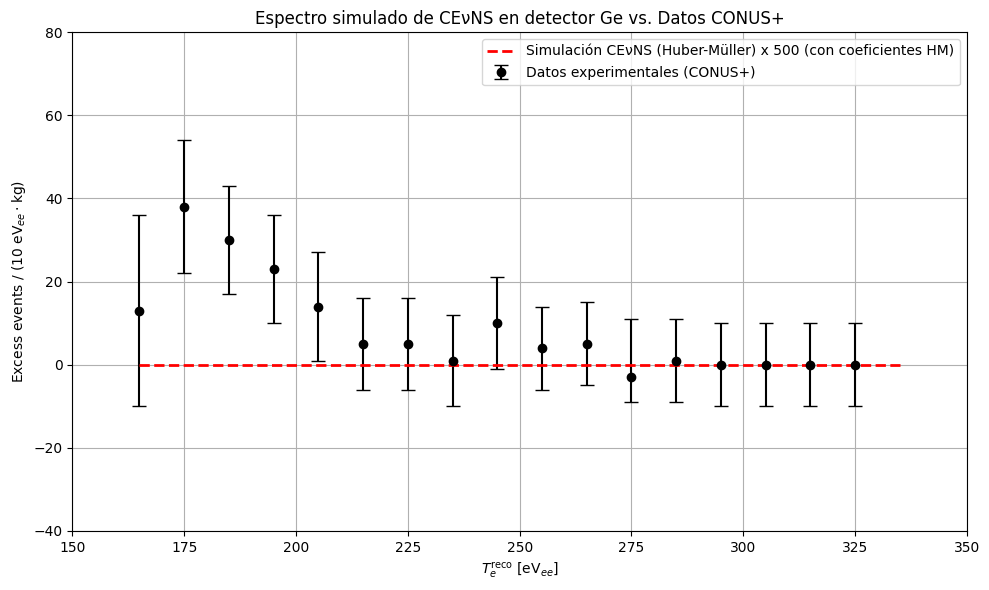


Gráfico de comparación generado.


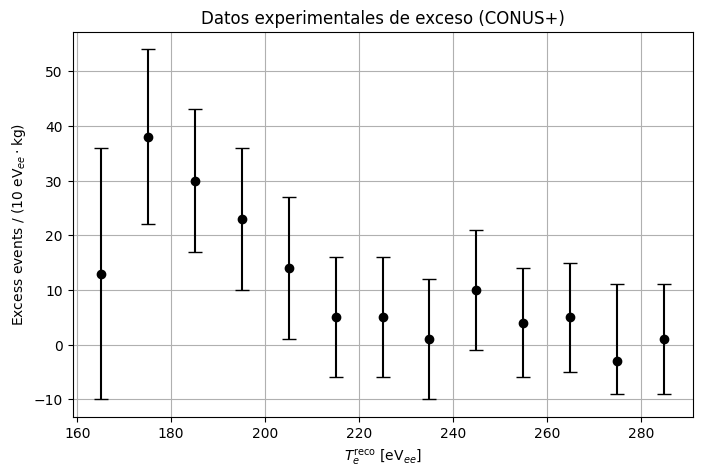

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(165, 286, 10)
y = np.array([13, 38, 30, 23, 14, 5, 5, 1, 10, 4, 5, -3, 1])
y_err_lower = np.array([23, 16, 13, 13, 13, 11, 11, 11, 11, 10, 10, 6, 10])
y_err_upper = np.array([23, 16, 13, 13, 13, 11, 11, 11, 11, 10, 10, 14, 10])
yerr = np.vstack((y_err_lower, y_err_upper))

plt.figure(figsize=(8,5))
plt.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)
plt.xlabel(r'$T_e^{\rm reco}$ [eV$_{ee}$]')
plt.ylabel('Excess events / (10 eV$_{ee}\cdot$kg)')
plt.title('Datos experimentales de exceso (CONUS+)')
plt.grid(True)
plt.show()


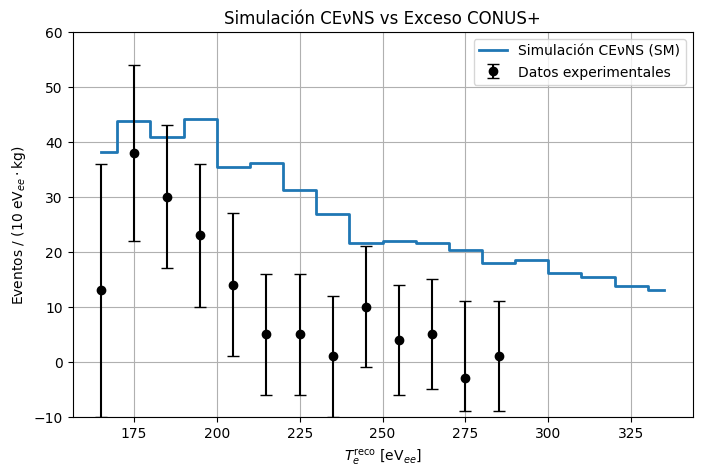

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

# ——————————————————————————————————————————————————————
# 0) Parámetros de exposición
# ——————————————————————————————————————————————————————
exposure_kgd = 327  # exposición CONUS+: 327 kg·días

# ——————————————————————————————————————————————————————
# 1) Espectro de antineutrinos Huber–Müller combinado
# ——————————————————————————————————————————————————————
f_U235, f_Pu239, f_U238, f_Pu241 = 0.55, 0.32, 0.07, 0.06
huber_coeffs = {
    'U235': np.array([3.2170, -3.111,  1.395, -0.369,  0.04445, -0.002053]),
    'Pu239':np.array([6.413,  -7.432,  3.535,  -0.882,   0.1025,  -0.00455]),
    'U238': np.array([0.4833,  0.1927, -0.1283, -0.006762, 0.002233, -0.0001536]),
    'Pu241':np.array([3.251,  -3.204,  1.428,  -0.3675,  0.04257, -0.001896]),
}
def neutrino_spectrum(E_nu_eV):
    E = E_nu_eV * 1e-6  # eV → MeV
    φ = np.zeros_like(E)
    for frac, iso in zip([f_U235, f_Pu239, f_U238, f_Pu241],
                         ['U235','Pu239','U238','Pu241']):
        a    = huber_coeffs[iso]
        poly = sum(a[k]*E**k for k in range(6))
        φ   += frac * np.exp(poly)
    return φ

# ——————————————————————————————————————————————————————
# 2) Factor de forma de Helm
# ——————————————————————————————————————————————————————
def helm_form_factor(q_eV):
    A  = 73   #Numero de masa
    R0, σ = 1.2*A**(1/3), 0.5     # σ SE SACO DE https://sci-hub.se/https://doi.org/10.1016/S0927-6505(96)00047-3
    R1    = np.sqrt(R0**2 - 5*σ**2)
    qr    = q_eV * 1e-6
    x     = qr * R1
    FF    = np.ones_like(x)
    mask  = x != 0  #evitamos las diviciones por cero
    FF[mask] = (3*(np.sin(x[mask]) - x[mask]*np.cos(x[mask])) \
               / x[mask]**3) * np.exp(-0.5*(qr[mask]*σ)**2)
    return FF

# ——————————————————————————————————————————————————————
# 3) Sección eficaz SM (Ec. 1)
# ——————————————————————————————————————————————————————

GF, sin2thW = 1.1663787e-5, 0.23126  #Constante de Fermi, ángulo de mezcla de Weinberg
Z, N        = 32, 41
M_nuc       = (Z+N) * 0.9315e9 #Número atómico y Número de neutrones
def dsigma_dER_SM(E_nu, ER):
    QW   = N - (1 - 4*sin2thW)*Z
    q    = np.sqrt(2*M_nuc*ER)
    pref = GF**2/(4*np.pi) * QW**2 * M_nuc
    K  = 1 - (M_nuc*ER)/(2*E_nu**2)
    return pref * K * helm_form_factor(q)**2

# ——————————————————————————————————————————————————————
# 4) Quenching de Lindhard
# ——————————————————————————————————————————————————————
def lindhard_quench(ER, k=0.157):
    eps = 11.5 * ER * Z**(-7/3)
    g   = 3*eps**0.15 + 0.7*eps**0.6 + eps
    return k * g * ER

# ——————————————————————————————————————————————————————
# 5) Factor de Fano y eficiencia de carga
# ——————————————————————————————————————————————————————
Fano, W_Ge = 0.13, 2.96
#Es una constante adimensional que describe la calidad del semiconductor en la producción de pares electrón-hueco. Un valor típico para Germanio es alrededor de 0.13.
#Es la energía promedio (en eV) requerida para crear un solo par electrón-hueco en Germanio a la temperatura de operación de los detectores (generalmente ∼77 K o temperatura de nitrógeno líquido).
def apply_fano(Eion):
    μ = Eion/W_Ge #media
    σ = np.sqrt(Fano*μ) #promedio
    return np.random.normal(loc=μ, scale=σ) * W_Ge

def efficiency_curve(Emeas):
    return 0.5 * (1 + erf((Emeas - 160)/20))

# ——————————————————————————————————————————————————————
# 6) Smearing + umbral + eficiencia
# ——————————————————————————————————————————————————————
def smear_and_threshold(Eion, fwhm=100, threshold=160):
    σ   = fwhm/2.355
    Em  = Eion + np.random.normal(0, σ, size=Eion.size)  #simula el ruido instrumental adicional que afecta la medición de energía en un detector real.
    mask = (Em >= threshold) & (np.random.rand(Em.size) < efficiency_curve(Em))
    return Em[mask]

# ——————————————————————————————————————————————————————
# 7) Muestreo de recoils CEνNS
# ——————————————————————————————————————————————————————
def sample_recoils(E_nu, n=1):
    ER_max = 2*E_nu**2/(M_nuc + 2*E_nu)
    ERs    = np.random.uniform(0, ER_max, size=n)
    p      = dsigma_dER_SM(E_nu, ERs)
    if p.max()==0: return np.zeros(0)
    return ERs[np.random.rand(n) < p/p.max()]

# ——————————————————————————————————————————————————————
# 8) Pipeline Monte Carlo completo
# ——————————————————————————————————————————————————————
def run_simulation(Nu_samples=50000, fwhm=100, threshold=160, bins=None):
    E_vals = np.linspace(1e6,1e7,5000)
    spec   = neutrino_spectrum(E_vals)
    spec  /= spec.sum()
    E_nu   = np.random.choice(E_vals, size=Nu_samples, p=spec)

    recoils = np.concatenate([sample_recoils(E,1) for E in E_nu])
    Eion    = lindhard_quench(recoils)
    Eion_f  = apply_fano(Eion)
    Emeas   = smear_and_threshold(Eion_f, fwhm, threshold)

    counts, edges = np.histogram(Emeas, bins=bins)
    counts        = counts.astype(float)
    counts       /= np.diff(edges) * exposure_kgd
    centers       = 0.5*(edges[:-1] + edges[1:])
    return centers, counts

# ——————————————————————————————————————————————————————
# 9) Uso y gráfico con datos experimentales
# ——————————————————————————————————————————————————————
if __name__ == "__main__":
    bin_edges = np.arange(160, 341, 10)
    centers, counts = run_simulation(50000, 100, 160, bin_edges)

    # Datos experimentales
    x = np.arange(165, 286, 10)
    y = np.array([13, 38, 30, 23, 14, 5, 5, 1, 10, 4, 5, -3, 1])
    y_err_low = np.array([23,16,13,13,13,11,11,11,11,10,10,6,10])
    y_err_up  = np.array([23,16,13,13,13,11,11,11,11,10,10,14,10])
    yerr      = np.vstack((y_err_low, y_err_up))

    plt.figure(figsize=(8,5))
    plt.step(centers, 550*counts, where='mid', lw=2, label='Simulación CEνNS (SM)')
    plt.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=4, label='Datos experimentales')
    plt.xlabel(r'$T_e^{\rm reco}$ [eV$_{ee}$]')
    plt.ylabel('Eventos / (10 eV$_{ee}\cdot$kg)')
    plt.title('Simulación CEνNS vs Exceso CONUS+')
    plt.ylim(-10, 60)
    plt.legend()
    plt.grid(True)
    plt.show()



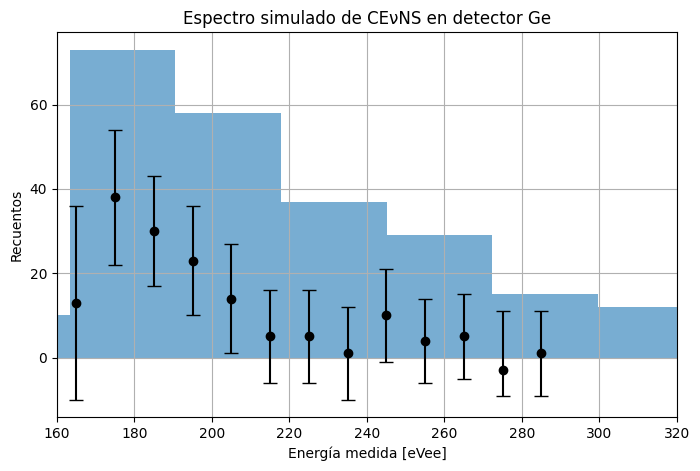

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
#  Simulación Monte Carlo para CEνNS en detector Ge
# ======================================================

# 1. Constantes físicas y parámetros del detector
GF      = 1.1663787e-5     # Constante de Fermi [GeV^-2]
sin2thW = 0.23126          # sin^2(theta_W) a cero momentum
Z, N    = 32, 41           # Ge aproximado: Z=32, N≈41 (Ge-73)
A       = Z + N            # ≈73
M       = A * 0.9315e9     # Masa nuclear [eV] (1 u ≈ 0.9315 GeV)

# 2. Espectro de antineutrinos (Huber–Müller)
def neutrino_spectrum(E_nu_eV):
    """
    Flujo de antineutrinos normalizado (placeholder).
    E_nu_eV en eV → convertir a MeV para la parametrización real.
    """
    E_MeV = E_nu_eV * 1e-6
    # TODO: implementar parametrización Huber–Müller real
    return np.exp(-E_MeV)

# 3. Factor de forma nuclear de Helm
def helm_form_factor(q_eV, A=A):
    """
    q_eV : transferido de momento [eV]
    """
    # Parámetros en fm
    R0    = 1.2 * A**(1/3)
    sigma = 0.5
    R1    = np.sqrt(R0**2 - 5*sigma**2)
    qr    = q_eV * 1e-6          # eV → fm^{-1}
    FF    = 3*(np.sin(qr*R1) - qr*R1*np.cos(qr*R1)) / ((qr*R1)**3)
    return FF * np.exp(-0.5*(qr*sigma)**2)

# 4. Sección eficaz diferencial CEνNS
def dsigma_dER(E_nu, ER):
    """
    E_nu : energía de neutrino [eV]
    ER   : energía de recoil nuclear [eV]
    """
    QW   = N - (1 - 4*sin2thW)*Z
    q    = np.sqrt(2 * M * ER)
    form = helm_form_factor(q)
    pref = GF**2 / (4 * np.pi) * QW**2 * M
    kin  = 1 - (M * ER) / (2 * E_nu**2)
    return pref * kin * form**2

# 5. Muestreo Monte Carlo de recoils (aceptación–rechazo simplificado)
def sample_recoils(E_nu, n_samples=1):
    ER_max = 2*E_nu**2 / (M + 2*E_nu)
    # muestreamos uniformemente y luego rechazamos según dσ/dER / (máximo)
    ER_try = np.random.uniform(0, ER_max, size=n_samples)
    probs  = dsigma_dER(E_nu, ER_try)
    if probs.max() == 0:
        return np.zeros_like(ER_try)
    accept = np.random.rand(n_samples) < probs/probs.max()
    return ER_try[accept]

# 6. Quenching de Lindhard
def lindhard_quenching(ER, Z=32, k=0.157):
    eps  = 11.5 * ER * Z**(-7/3)
    g    = 3*eps**0.15 + 0.7*eps**0.6 + eps
    Eion = k * g * ER
    return Eion

# 7. Respuesta del detector (smearing + umbral)
def smear_and_threshold(Eion, fwhm=100, threshold=160):
    sigma = fwhm / 2.355
    Emeas = Eion + np.random.normal(0, sigma, size=Eion.size)
    return Emeas[Emeas >= threshold]

# 8. Rutina principal
def run_simulation(Nu_samples=10000):
    # Muestrear energías de neutrino correctamente
    E_vals = np.linspace(1e6, 1e7, 1000)        # 1–10 MeV en eV
    spec   = neutrino_spectrum(E_vals)
    spec  /= spec.sum()                         # normalizar a suma=1
    E_nu   = np.random.choice(E_vals, size=Nu_samples, p=spec)

    # Muestreo de recoils y acumulación
    recoils = []
    for En in E_nu:
        ERs = sample_recoils(En, n_samples=1)
        recoils.extend(ERs)
    recoils = np.array(recoils)

    # Aplicar quenching y respuesta del detector
    Eion  = lindhard_quenching(recoils)
    Emeas = smear_and_threshold(Eion)

    x = np.arange(165, 286, 10)
    y = np.array([13, 38, 30, 23, 14, 5, 5, 1, 10, 4, 5, -3, 1])
    y_err_lower = np.array([23, 16, 13, 13, 13, 11, 11, 11, 11, 10, 10, 6, 10])
    y_err_upper = np.array([23, 16, 13, 13, 13, 11, 11, 11, 11, 10, 10, 14, 10])
    yerr = np.vstack((y_err_lower, y_err_upper))


    # Histograma final
    plt.figure(figsize=(8,5))

    plt.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)

    bins = np.linspace(0, np.percentile(Emeas, 99), 80)
    plt.hist(Emeas, bins=bins, histtype='stepfilled', alpha=0.6)
    plt.xlabel('Energía medida [eVee]')
    plt.ylabel('Recuentos')
    plt.title('Espectro simulado de CEνNS en detector Ge')
    plt.xlim(160, 320)    # fijar límites del eje x
    plt.grid(True)
    plt.show()

# ===== Ejecutar simulación de prueba =====
if __name__ == "__main__":
    run_simulation(Nu_samples=5000)

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 64)